# IND320 — Project work, part 2: Data Sources

**Mohammad el Meziani**

## Links

- GitHub repository: https://github.com/mokakao/ind320-mokakao
- Streamlit app: https://ind320-mokakaoo.streamlit.app
- Screencast: *(link added as a submission comment in Canvas)*

<div class="alert alert-block alert-info">
<h2>AI usage</h2>

I used Claude (through Claude Code in the terminal) as the main tool for this hand-in, and it is fair to say it did the heavy lifting on the code.

**What the AI did**

- Wrote the Python modules (`modules/nve.py`, `modules/entsoe_flows.py`, `modules/storage.py`), the Streamlit pages and this notebook, including the comments.
- Worked out the Cassandra table design and the Spark read/write code.
- Drafted this log and the text on the About page.

**What I did**

- Decided what to build and in what order, and checked the result against the assignment text point by point.
- Set up everything the code runs on: Docker and the Cassandra container, Java 17 and PySpark, the MongoDB Atlas cluster with its database user and IP access list, and the ENTSO-E account and security token.
- Transcribed the lectures and pulled out the requirements, including the changes Liland made to the task on 12 October.
- Tested the app, read through the code until I could explain what each part does, and recorded the screencast.

So the code is not typed by me, but every choice about what it should do, and all the checking that it actually does it, is mine. This is declared openly because the course allows AI use under category K3 as long as it is documented.
</div>

<div class="alert alert-block alert-success">
<h2>Log</h2>

The first thing I did was get the infrastructure in place, because none of it is instant. The ENTSO-E security token took a full day: you register, email their support team, and wait for them to enable API access. I sent that on 1 October and had the token the next morning. Liland warned in a lecture not to leave it until 38 hours before the deadline, and he was right.

Docker and Cassandra were already running from the database lectures, so the new work there was getting Spark to talk to Cassandra, which worked once the connector version was pinned to match PySpark. MongoDB Atlas was quick: a free M0 cluster in Stockholm, a database user, and the IP access list opened to 0.0.0.0/0 — which you have to do, because Streamlit Cloud runs from an address you do not control.

Swapping the CSV for the API was the easy part. The NVE API returns exactly the column names the CSV had, so the renaming from part 1 worked untouched. What surprised me is that none of the four endpoints take parameters — `HentOffentligData` hands you all 14 913 rows every time. So the download interval in the app trims right after the call, and the interval is part of the cache key, which is what makes changing it actually fetch again. I also noticed the areas endpoint lists four watercourse areas while only three have measurements.

ENTSO-E was slower in every sense. Two years of cross-border flow comes in 15-minute resolution — roughly 70 000 points per direction, about four minutes per request. Six series took fifteen minutes, so I cached the result to a parquet file instead of re-downloading it every time I wanted to test something. Denmark came back with fewer points than the others, which turned out to be resolution rather than missing data: Skagerrak is hourly for the earlier part of the period.

The real time sink was PySpark, in three rounds. Writing a pandas DataFrame to Cassandra failed with `No module named 'distutils'`, which Python 3.12 removed and PySpark 3.5 still imports; dropping the pandas bridge for plain rows with an explicit schema fixed it, and is better code anyway. Then Spark launched its workers with the system Python 3.9 against a 3.12 driver and refused to run, which `PYSPARK_PYTHON` sorted. The third one was the interesting one: 42 rows quietly vanished between writing and reading. Naive timestamps are converted using the driver's local time zone, and in Oslo the hour 02:00-03:00 exists twice when the clocks go back, so two UTC instants collided on a primary key and one overwrote the other. Counting rows instead of trusting them is what caught it.

The Streamlit work was mostly restructuring after the 12 October update: the slider now controls the download rather than the display, and the area radio drives the table as well as the plots, so the table rows became areas instead of columns. Putting the shared controls in one function with session-state keys means the choices follow you between pages instead of resetting.
</div>

## Setup

Everything that talks to an API or a database lives in `modules/`, so this notebook and the Streamlit app use exactly the same code instead of two copies that drift apart.

In [1]:
import sys
from pathlib import Path

# The notebook sits in notebooks/, the modules one level up. Adding the project
# root to the path lets both this file and the app import the same code.
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from modules import entsoe_flows, nve, storage

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

print("Project root:", PROJECT_ROOT)

Project root: /Users/moa/Desktop/ind320/prosjekt


---

# 1. Reservoir data from the NVE API

Part 1 of this project read `data/reservoirs.csv`. That file is now deleted, and everything comes from the Magasinstatistikk API instead.

## 1.1 Which areas does the API cover?

The task asks me to identify the areas of Norway the API covers, so that is the first call.

In [2]:
areas = nve.fetch_areas()
areas

,name,long_name,description,area_type,area_number
0,Norge,Norge,Hele landet,NO,0
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


Three types of area:

- **NO** — the whole country, a single area.
- **EL** — the five electricity price areas, NO1 to NO5. These are what the power price is quoted per.
- **VASS** — the watercourse areas, grouped by geography rather than by market.

Note that the endpoint lists **four** watercourse areas, but as the next cell shows, VASS4 has no measurements. Only nine of the ten areas carry data.

In [3]:
# Download everything once so the shape of the data is visible before any
# filtering happens.
reservoirs = nve.fetch_reservoirs()

print(f"{len(reservoirs):,} rows".replace(",", " "))
print(f"{reservoirs['date'].min():%d %b %Y} to {reservoirs['date'].max():%d %b %Y}")

reservoirs.groupby(["area_type", "area_number"]).size().rename("rows").to_frame()

14 913 rows
08 Jan 1995 to 04 Oct 2026


rows
area_type area_number      
EL        1            1657
          2            1657
          3            1657
          4            1657
          5            1657
NO        0            1657
VASS      1            1657
          2            1657
          3            1657

In [4]:
reservoirs.head()

,date,area_type,area_number,iso_year,iso_week,fill_level,capacity_TWh,stored_TWh,next_publication_date,fill_level_previous_week,fill_level_change
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,1-01-01,0.583705,0.033869
1,1995-01-15,EL,1,1995,2,0.579205,6.003264,3.477117,1-01-01,0.617574,-0.038369
2,1995-01-22,EL,1,1995,3,0.546713,6.003264,3.282063,1-01-01,0.579205,-0.032491
3,1995-01-29,EL,1,1995,4,0.504545,6.003264,3.028916,1-01-01,0.546713,-0.042168
4,1995-02-05,EL,1,1995,5,0.465335,6.003264,2.793528,1-01-01,0.504545,-0.039210


In [5]:
reservoirs.info()

<class 'pandas.DataFrame'>
RangeIndex: 14913 entries, 0 to 14912
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      14913 non-null  datetime64[us]
 1   area_type                 14913 non-null  str           
 2   area_number               14913 non-null  int64         
 3   iso_year                  14913 non-null  int64         
 4   iso_week                  14913 non-null  int64         
 5   fill_level                14913 non-null  float64       
 6   capacity_TWh              14913 non-null  float64       
 7   stored_TWh                14913 non-null  float64       
 8   next_publication_date     14913 non-null  datetime64[us]
 9   fill_level_previous_week  14913 non-null  float64       
 10  fill_level_change         14913 non-null  float64       
dtypes: datetime64[us](2), float64(5), int64(3), str(1)
memory usage: 1.3 MB


In [6]:
reservoirs.describe()

,date,area_number,iso_year,iso_week,fill_level,capacity_TWh,stored_TWh,next_publication_date,fill_level_previous_week,fill_level_change
count,14913,14913.000000,14913.000000,14913.000000,14913.000000,14913.000000,14913.000000,14913,14913.000000,14913.000000
mean,2010-11-21 00:00:00,2.333333,2010.383826,26.435124,0.618892,29.145860,18.141091,0487-11-19 14:31:45.371160,0.618891,0.000002
min,1995-01-08 00:00:00,0.000000,1995.000000,1.000000,0.051653,6.003264,0.310089,0001-01-01 00:00:00,0.051653,-0.242484
25%,2002-12-15 00:00:00,1.000000,2002.000000,13.000000,0.456675,17.390587,7.325503,0001-01-01 00:00:00,0.456715,-0.022364
50%,2010-11-21 00:00:00,2.000000,2010.000000,26.000000,0.648049,23.237715,14.503712,0001-01-01 00:00:00,0.648057,-0.007005
75%,2018-10-28 00:00:00,3.000000,2018.000000,39.000000,0.801892,34.043590,22.202377,0001-01-01 00:00:00,0.801822,0.016298
max,2026-10-04 00:00:00,5.000000,2026.000000,53.000000,1.020072,87.437580,84.518060,2026-10-14 13:00:00,1.020037,0.345632
std,NaN,1.490762,9.167891,15.011609,0.214720,22.739069,15.963174,NaN,0.214709,0.031342


Two things worth noticing, both of which carried over from part 1:

- The rows arrive in **no particular order**, and there are nine areas stacked on top of each other. Sorting on date alone is not enough — it gives nine values per week in a random order. `fetch_reservoirs` sorts on area and then date.
- `next_publication_date` is `0001-01-01` on most rows. It is a placeholder, not a date, so it is parsed leniently and becomes `NaT`.

## 1.2 Recreating the plots from part 1

Same plots as last time, but the data now come over the wire. Norway as a whole is used here, the same choice as in part 1.

In [7]:
norway = nve.one_area(reservoirs, "NO", 0)
norway.tail()

,fill_level,fill_level_previous_week,fill_level_change,capacity_TWh,stored_TWh
date,,,,,
2026-09-06,0.636207,0.634423,0.001784,87.43758,55.628372
2026-09-13,0.642904,0.636209,0.006695,87.43758,56.213930
2026-09-20,0.666386,0.642900,0.023486,87.43758,58.267190
2026-09-27,0.678552,0.666392,0.012160,87.43758,59.330967
2026-10-04,0.678859,0.678495,0.000364,87.43758,59.357765


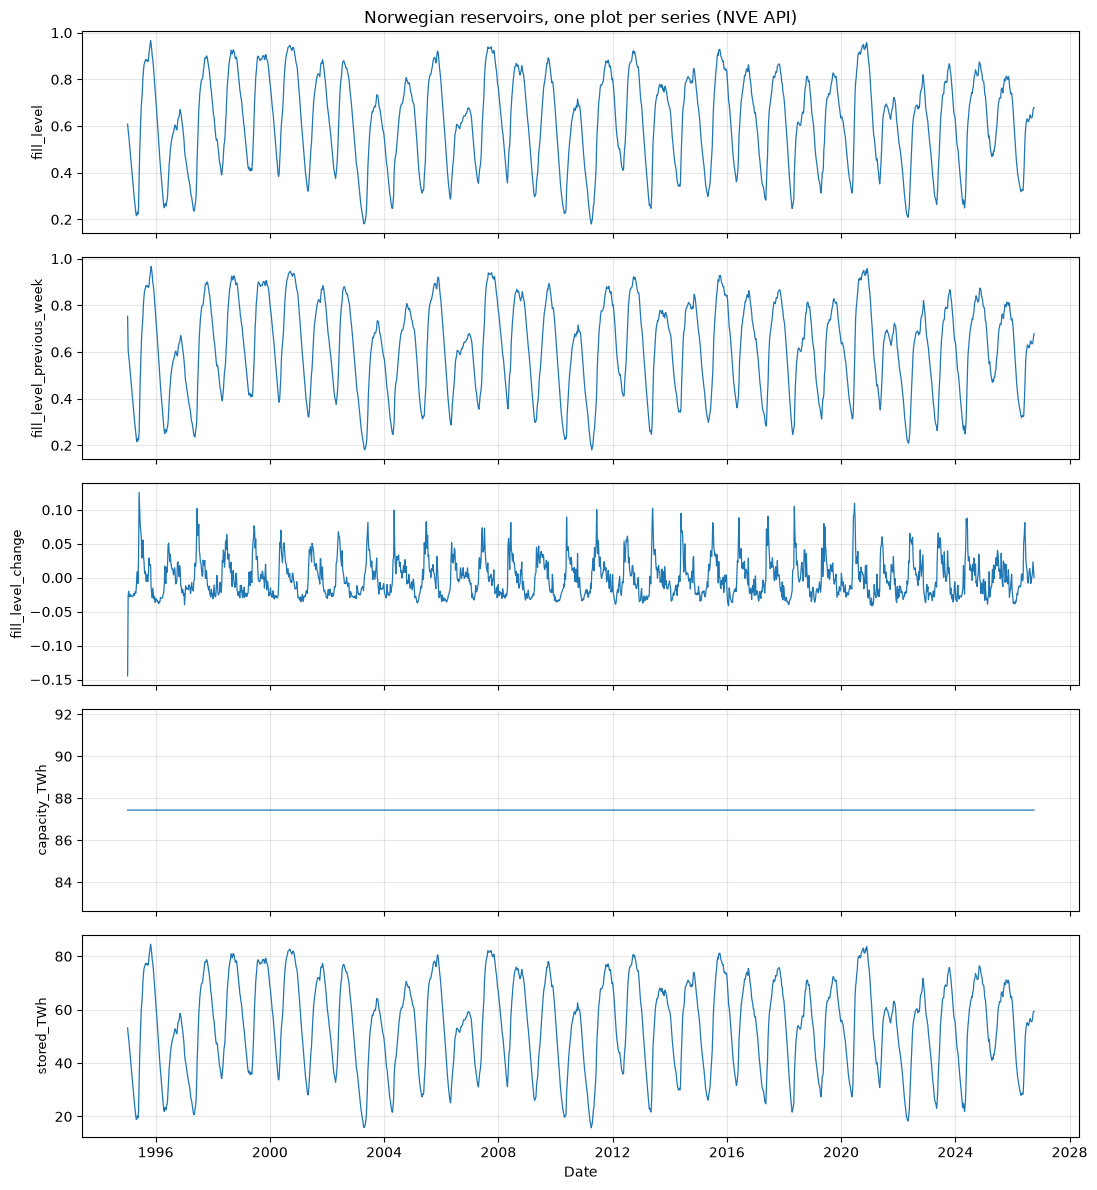

In [8]:
# One plot per column, which is what part 1 asked for.
fig, axes = plt.subplots(len(norway.columns), 1, figsize=(11, 12), sharex=True)

for ax, column in zip(axes, norway.columns):
    ax.plot(norway.index, norway[column], linewidth=0.9)
    ax.set_ylabel(column, fontsize=9)
    ax.grid(alpha=0.3)

axes[0].set_title("Norwegian reservoirs, one plot per series (NVE API)")
axes[-1].set_xlabel("Date")
fig.tight_layout()
plt.show()

And all of them in one plot. The point of doing it twice is to show why the scaling is needed: capacity is around 87 TWh, the fill level is a share between 0 and 1, and the weekly change is almost zero. On a shared axis you see two lines and three flat ones.

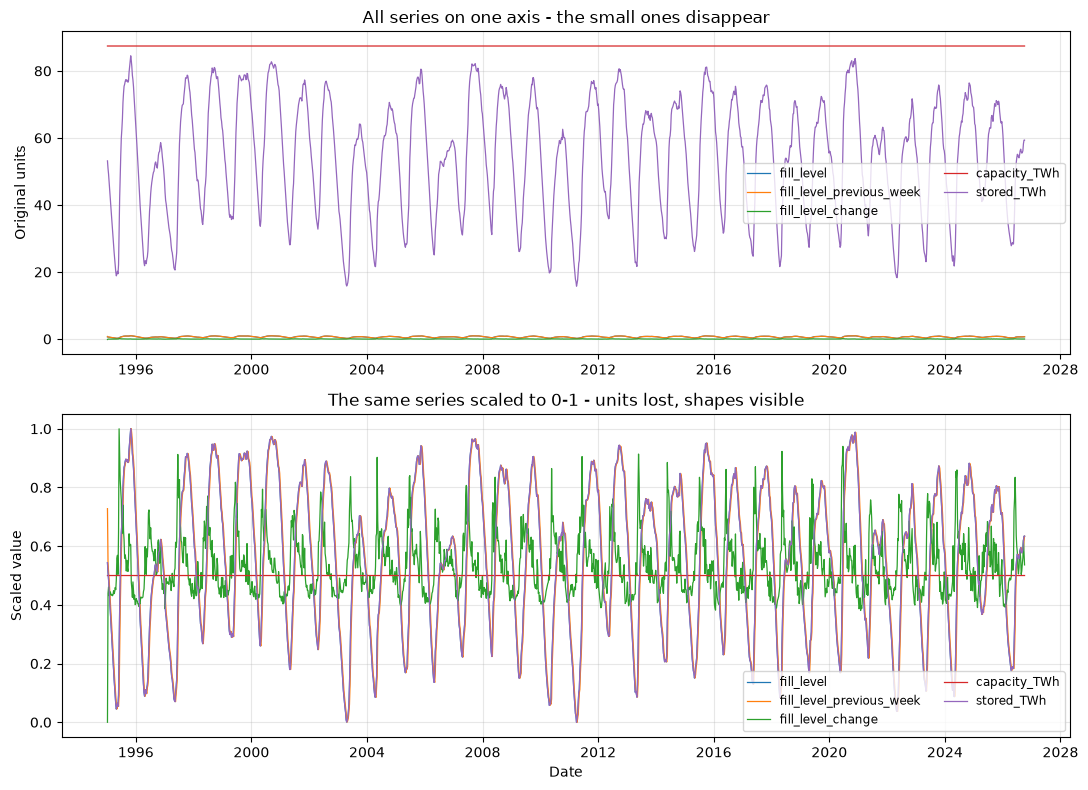

In [9]:
fig, (raw_ax, scaled_ax) = plt.subplots(2, 1, figsize=(11, 8))

# Honest version: everything on one axis, units intact.
for column in norway.columns:
    raw_ax.plot(norway.index, norway[column], label=column, linewidth=0.9)
raw_ax.set_title("All series on one axis - the small ones disappear")
raw_ax.set_ylabel("Original units")
raw_ax.legend(fontsize="small", ncol=2)
raw_ax.grid(alpha=0.3)

# Readable version: each series scaled to 0-1 so the shapes can be compared.
scaled = norway.copy()
for column in scaled.columns:
    low, high = scaled[column].min(), scaled[column].max()
    scaled[column] = (scaled[column] - low) / (high - low) if high > low else 0.5

for column in scaled.columns:
    scaled_ax.plot(scaled.index, scaled[column], label=column, linewidth=0.9)
scaled_ax.set_title("The same series scaled to 0-1 - units lost, shapes visible")
scaled_ax.set_ylabel("Scaled value")
scaled_ax.set_xlabel("Date")
scaled_ax.legend(fontsize="small", ncol=2)
scaled_ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

The yearly rhythm is clear in the scaled version: the reservoirs fill through autumn and empty through winter.

## 1.3 The price areas separately

The app's radio button plots every area number of a chosen type. Here is what that looks like for the five price areas.

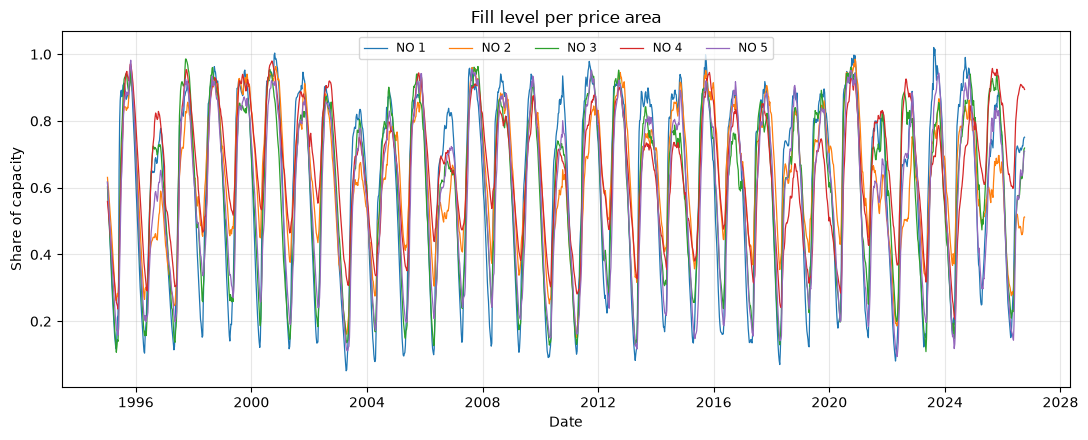

In [10]:
by_area = nve.wide(reservoirs, "EL", "fill_level")

fig, ax = plt.subplots(figsize=(11, 4.5))
for number in by_area.columns:
    ax.plot(by_area.index, by_area[number], label=f"NO {number}", linewidth=0.9)

ax.set_title("Fill level per price area")
ax.set_ylabel("Share of capacity")
ax.set_xlabel("Date")
ax.legend(fontsize="small", ncol=5)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

---

# 2. Cross-border power flow from ENTSO-E

The second source is the ENTSO-E Transparency Platform, dataset *cross-border physical flows*. It needs a free account and a security token, which is kept in `.streamlit/secrets.toml` and never committed.

Three cables, both directions, two years:

| Cable | Between | ENTSO-E areas |
| --- | --- | --- |
| Skagerrak | Norway and Denmark | NO_2 – DK_1 |
| NordLink | Norway and Germany | NO_2 – DE_LU |
| North Sea Link | Norway and England | NO_2 – GB |

All three run out of price area NO2 in southwest Norway.

The data come in 15-minute resolution, so two years of one direction is about 70 000 points and takes roughly four minutes to fetch. Six series is close to half an hour, so the result is cached to a parquet file and `load_or_download` only hits the API when the cache is missing.

In [11]:
token = storage.secrets()["entsoe_token"]

flows = entsoe_flows.load_or_download(token, years=2)

print(f"{len(flows):,} rows".replace(",", " "))
print(f"{flows['timestamp'].min()} to {flows['timestamp'].max()} (UTC)")

flows.groupby(["country", "direction"]).size().rename("rows").to_frame()

394 980 rows
2024-10-12 22:00:00 to 2026-10-12 21:45:00 (UTC)


rows
country direction       
Denmark export     57330
        import     57330
England export     70080
        import     70080
Germany export     70080
        import     70080

In [12]:
flows.head()

,timestamp,country,direction,mw
0,2024-10-12 22:00:00,Denmark,export,0.00
1,2024-10-12 23:00:00,Denmark,export,89.05
2,2024-10-13 00:00:00,Denmark,export,0.00
3,2024-10-13 01:00:00,Denmark,export,0.01
4,2024-10-13 02:00:00,Denmark,export,0.00


In [13]:
# The three cables do not have the same number of points, which is worth a look
# before anything is built on top of them.
flows.groupby("country")["timestamp"].agg(["min", "max", "count"])

,min,max,count
country,,,
Denmark,2024-10-12 22:00:00,2026-10-12 21:45:00,114660
England,2024-10-12 22:00:00,2026-10-12 21:45:00,140160
Germany,2024-10-12 22:00:00,2026-10-12 21:45:00,140160


Denmark has noticeably fewer rows than the other two. The reason is resolution, not missing data: ENTSO-E moved the Nordic market to 15-minute settlement partway through the period, and the Skagerrak series is hourly before that point. England and Germany are 15-minute throughout, giving exactly 70 080 points for two years.

This is a good argument for averaging everything to hourly before comparing the cables - which is what the Spark step below does anyway.

`direction` is `export` when power leaves Norway and `import` when it comes in. ENTSO-E reports the two directions as separate series, so both can be above zero within the same hour.

---

# 3. Into Cassandra, using Spark

The task asks for the data to be inserted into Cassandra **using Spark**, not the plain driver. The driver is still used for the one thing Spark cannot do — creating the keyspace and the table.

The table is partitioned on `(country, direction)` and clustered by time, which matches how it is read back: always one cable and one direction over a period. That gives six partitions of about 70 000 rows each.

Every column name is lowercase on purpose. Cassandra folds unquoted names to lowercase while Spark is case sensitive, and mixing the two gives a column-not-found error that is genuinely confusing the first time you see it.

In [14]:
session = storage.cassandra_session()
storage.create_flow_table(session, reset=True)

session.execute(
    f"SELECT table_name FROM system_schema.tables WHERE keyspace_name = '{storage.KEYSPACE}'"
).all()

[Row(table_name='crossborder_flows')]

In [15]:
# Starting Spark downloads the Cassandra connector from Maven the first time,
# so this cell takes a while on a cold run.
spark = storage.spark_session()
print("Spark", spark.version)

26/10/13 13:42:54 WARN Utils: Your hostname, Mohammad-sin-MacBook-Air.local resolves to a loopback address: 127.0.0.1; using 192.168.31.90 instead (on interface en0)
26/10/13 13:42:54 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /Users/moa/.ivy2/cache
The jars for the packages stored in: /Users/moa/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-4d003e55-42ed-435c-ac80-7e7493ee4991;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central


:: loading settings :: url = jar:file:/Users/moa/Desktop/ind320/kurs/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0.3 in central
	found org.apache.cassandra#java-driver-mapper-runtime;4.18.1 in central
	found org.apache.cassandra#java-driver-query-builder;4.18.1 in central
	found org.apache.commons#commons-lang3;3.10 in central
	found com.thoughtworks.paranamer#paranamer;2.8 in central
	found org.scala-lang#scala-reflect;2.12.19 in central
:: resolution report :: resolve 181ms :: artifacts dl 7ms
	:: modules in use:
	com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 from central in [default]
	com.datastax.oss#native-protocol;1.5.1 from

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 3.5.1


In [16]:
rows_written = storage.write_flows(spark, flows)
print(f"{rows_written:,} rows written to Cassandra through Spark".replace(",", " "))

26/10/13 13:42:59 WARN TaskSetManager: Stage 0 contains a task of very large size (7735 KiB). The maximum recommended task size is 1000 KiB.


394 980 rows written to Cassandra through Spark


## 3.1 Reading it back with Spark

Confirming the round trip before anything is built on top of it. The row count is worth checking rather than assuming - Cassandra overwrites silently when two rows share a primary key, so a quiet mismatch here would never raise an error.

In [17]:
from_cassandra = storage.read_flows(spark)

written = len(flows)
stored = from_cassandra.count()

print(f"Written: {written:,}".replace(",", " "))
print(f"Stored:  {stored:,}".replace(",", " "))
print("Match" if written == stored else f"MISMATCH: {written - stored} rows lost")

from_cassandra.show(5)

Written: 394 980
Stored:  394 980
Match
+-------+---------+-------------------+---+
|country|direction|                 ts| mw|
+-------+---------+-------------------+---+
|England|   import|2024-10-12 22:00:00|0.0|
|England|   import|2024-10-12 22:15:00|0.0|
|England|   import|2024-10-12 22:30:00|0.0|
|England|   import|2024-10-12 22:45:00|0.0|
|England|   import|2024-10-12 23:00:00|0.0|
+-------+---------+-------------------+---+
only showing top 5 rows



This check earned its place. The first run stored 42 rows fewer than it wrote.

The cause was time zones. The timestamps are naive UTC in pandas, and PySpark converts a naive datetime using the driver's local time zone - which here is Europe/Oslo. On the night the clocks go back, the hour 02:00-03:00 happens twice in Oslo, so two different UTC instants ended up as the same value. Since `ts` is part of the primary key, the second one quietly overwrote the first.

The arithmetic matched exactly: two autumn transitions, four quarter-hours each, across four of the six series, plus the Danish pair which was still hourly in October 2024. That is 42.

The fix is one call - `tz_localize("UTC")` before handing the rows to Spark - so the timestamps arrive as real instants instead of wall-clock readings. It is the same lesson as the strange time column in part 1: dates that look fine are worth counting anyway.

---

# 4. Spark: pick the columns, shrink the data

`read_flows` already selects only the four columns that matter. The next step averages the 15-minute values into hourly ones.

Two reasons for doing that:

- Two years of quarter-hourly data for six series is about 420 000 rows. The free MongoDB tier has 512 MB of storage and a weekly transfer limit, and a dashboard plot cannot show that much detail anyway.
- An hourly mean of megawatts is still megawatts, so one hour of it is also the energy in MWh. That is what makes the yearly sums in the pie chart meaningful.

The grouping happens in Spark, and only the small result is pulled back with `toPandas()`.

In [18]:
hourly = storage.hourly_from_spark(spark)

print(f"{len(hourly):,} hourly rows".replace(",", " "))
print(f"{len(flows):,} raw rows in, roughly a quarter back out".replace(",", " "))

hourly.head()

105 120 hourly rows
394 980 raw rows in  roughly a quarter back out


,country,direction,timestamp,mw,year,month
0,Denmark,export,2024-10-13 00:00:00,0.00,2024,10
1,Denmark,export,2024-10-13 01:00:00,89.05,2024,10
2,Denmark,export,2024-10-13 02:00:00,0.00,2024,10
3,Denmark,export,2024-10-13 03:00:00,0.01,2024,10
4,Denmark,export,2024-10-13 04:00:00,0.00,2024,10


## 4.1 Pie chart: how much went each way over a year

One cable, one year, with the two slices being the amount out of and into Norway.

Pie charts are a poor way of comparing areas by eye, so the percentage is written on each slice.

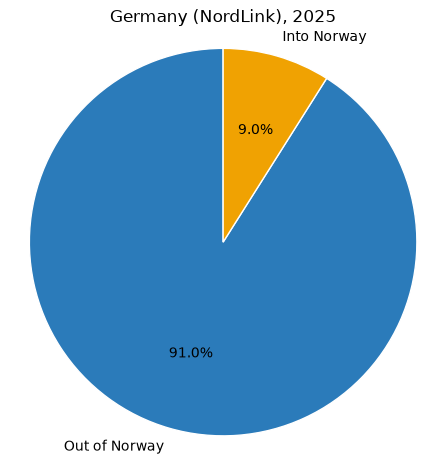

Out: 7.79 TWh
In:  0.77 TWh
Net: +7.02 TWh


In [19]:
PIE_COUNTRY = "Germany"
PIE_YEAR = 2025

year_slice = hourly[(hourly["country"] == PIE_COUNTRY) & (hourly["year"] == PIE_YEAR)]

# Hourly MW summed over a year gives MWh; dividing by a million gives TWh,
# which is the same unit the reservoir data use.
totals = year_slice.groupby("direction")["mw"].sum().reindex(["export", "import"]) / 1_000_000

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(
    totals,
    labels=["Out of Norway", "Into Norway"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2b7bba", "#f0a202"],
    wedgeprops={"edgecolor": "white"},
)
ax.set_title(f"{PIE_COUNTRY} ({entsoe_flows.CONNECTIONS_BY_COUNTRY[PIE_COUNTRY]}), {PIE_YEAR}")
ax.axis("equal")
plt.show()

print(f"Out: {totals['export']:.2f} TWh")
print(f"In:  {totals['import']:.2f} TWh")
print(f"Net: {totals['export'] - totals['import']:+.2f} TWh")

## 4.2 Line plot: the first month of a year

Separate lines for each connection and each direction, so six lines. Imports are dashed so the pairs are easy to tell apart.

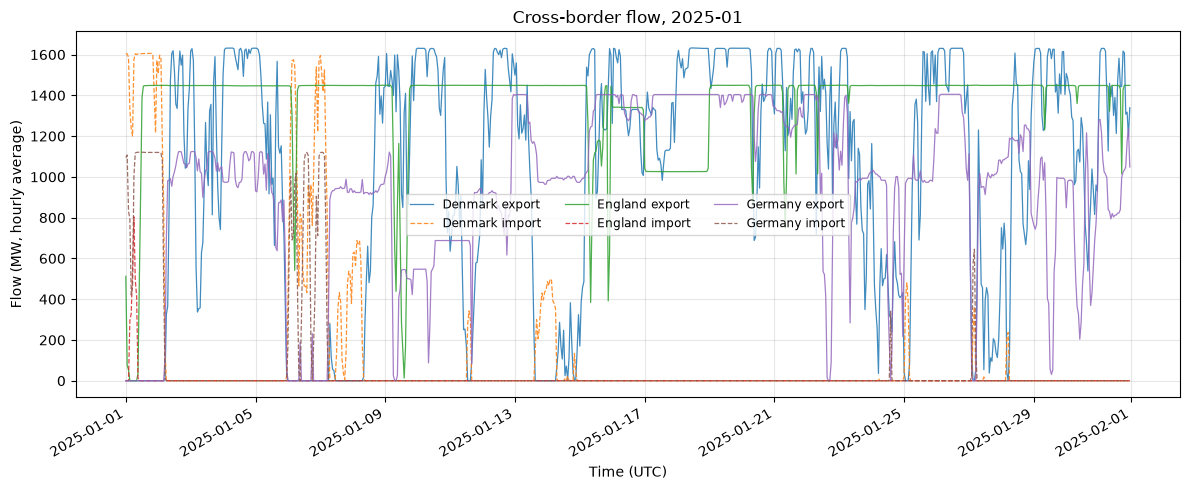

In [20]:
LINE_YEAR = 2025
LINE_MONTH = 1

month_slice = hourly[(hourly["year"] == LINE_YEAR) & (hourly["month"] == LINE_MONTH)]

fig, ax = plt.subplots(figsize=(12, 5))
for (country, direction), group in month_slice.groupby(["country", "direction"]):
    ax.plot(
        group["timestamp"],
        group["mw"],
        label=f"{country} {direction}",
        linewidth=0.9,
        alpha=0.85,
        linestyle="-" if direction == "export" else "--",
    )

ax.set_title(f"Cross-border flow, {LINE_YEAR}-{LINE_MONTH:02d}")
ax.set_ylabel("Flow (MW, hourly average)")
ax.set_xlabel("Time (UTC)")
ax.legend(fontsize="small", ncol=3)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

---

# 5. Into MongoDB

The hourly data are what the Streamlit app reads, so they go to MongoDB Atlas. The collection is emptied first — re-running this notebook should replace the data, not stack another copy on top, and the free tier only has 512 MB.

An index on `(year, country, direction)` keeps the app's queries quick; it only ever asks for one year at a time.

In [21]:
document_count = storage.write_hourly_to_mongo(hourly)
print(f"{document_count:,} documents in MongoDB".replace(",", " "))

105 120 documents in MongoDB


In [22]:
# Read a few back out, the same way the app does.
collection = storage.mongo_collection()

print("Years stored:    ", sorted(collection.distinct("year")))
print("Connections:     ", sorted(collection.distinct("country")))
print("Directions:      ", sorted(collection.distinct("direction")))

pd.DataFrame(list(collection.find({}, {"_id": 0}).limit(5)))

Years stored:     [2024, 2025, 2026]


Connections:      ['Denmark', 'England', 'Germany']


Directions:       ['export', 'import']


,country,direction,timestamp,mw,year,month
0,Denmark,export,2024-10-13 00:00:00,0.00,2024,10
1,Denmark,export,2024-10-13 01:00:00,89.05,2024,10
2,Denmark,export,2024-10-13 02:00:00,0.00,2024,10
3,Denmark,export,2024-10-13 03:00:00,0.01,2024,10
4,Denmark,export,2024-10-13 04:00:00,0.00,2024,10


In [23]:
# Shut Spark down so the notebook does not leave a JVM running.
spark.stop()
print("Spark stopped")

Spark stopped


---

# 6. Sources

**Data**

- NVE Magasinstatistikk API — https://biapi.nve.no/magasinstatistikk/swagger/index.html — the reservoir data, replacing the CSV from part 1. The description of what the figures mean is at https://www.nve.no/energi/analyser-og-statistikk/magasinstatistikk/
- ENTSO-E Transparency Platform — https://transparency.entsoe.eu/ — cross-border physical flows. API reference at https://documenter.getpostman.com/view/7009892/2s93JtP3F6

**Code and documentation**

- `entsoe-py` — the Python client used for the ENTSO-E calls. The Pandas client returns a `Series` indexed by time, which saved parsing the XML by hand.
- Course book, *Databases* chapter — the Cassandra keyspace setup and the Spark write pattern (`write.format("org.apache.spark.sql.cassandra")...mode("append").save()`) come from there.
- Course book, *Spark* chapter — the warning about PySpark being case sensitive while Cassandra is not, which is why every column name here is lowercase.
- Streamlit documentation for `st.pills`, `st.radio`, `st.columns` and `st.column_config.LineChartColumn`.
- PyMongo documentation for `insert_many` and `create_index`.

**Tools**

- Claude (Claude Code) — see the AI usage section at the top.